In [1]:
# --- Ran in Terminal to install nltk Package ----

#python -m pip install nltk

In [2]:
 %pip install pandas matplotlib seaborn nltk ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import urllib.request
import zipfile
import io
import csv
import os

In [4]:
# Download the dataset directly from UCI
url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"

response = urllib.request.urlopen(url)
zip_file = zipfile.ZipFile(io.BytesIO(response.read()))

# Load the three review files
dataframes = []

files = {
    "amazon_cells_labelled.txt": "Amazon",
    "imdb_labelled.txt": "IMDb",
    "yelp_labelled.txt": "Yelp"
}

for filename, source in files.items():
    matching_file = next(
        name for name in zip_file.namelist()
        if name.endswith("/" + filename)
        and "__MACOSX" not in name
        and "/._" not in name
    )

    temp_df = pd.read_csv(
        zip_file.open(matching_file),
        sep="\t",
        header=None,
        names=["Review", "Original_Label"],
        quoting=csv.QUOTE_NONE
    )

    temp_df["Source"] = source
    dataframes.append(temp_df)

# Build a fresh DataFrame
df = pd.concat(dataframes, ignore_index=True)

print("Dataset shape:", df.shape)
print("\nRows per source:")
print(df["Source"].value_counts())


Dataset shape: (3000, 3)

Rows per source:
Source
Amazon    1000
IMDb      1000
Yelp      1000
Name: count, dtype: int64


In [5]:
# Initialize VADER


# Download the VADER sentiment dictionary
nltk.download("vader_lexicon")

from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Create the sentiment analyzer
analyzer = SentimentIntensityAnalyzer()

print("VADER is ready!")


[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\khay\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


VADER is ready!


In [6]:

# Calculate sentiment scores for each review
sentiment_scores = df["Review"].apply(
    lambda review: analyzer.polarity_scores(str(review))
)

# Add sentiment scores to the dataset
df["Negative_Score"] = sentiment_scores.apply(lambda x: x["neg"])
df["Neutral_Score"] = sentiment_scores.apply(lambda x: x["neu"])
df["Positive_Score"] = sentiment_scores.apply(lambda x: x["pos"])
df["Compound_Score"] = sentiment_scores.apply(lambda x: x["compound"])

# Classify each review
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

df["Predicted_Sentiment"] = df["Compound_Score"].apply(
    classify_sentiment
)

display(df.head())


,Review,Original_Label,Source,Negative_Score,Neutral_Score,Positive_Score,Compound_Score,Predicted_Sentiment
0,So there is no way for me to plug it in here i...,0,Amazon,0.120,0.880,0.000,-0.3535,Negative
1,"Good case, Excellent value.",1,Amazon,0.000,0.100,0.900,0.8402,Positive
2,Great for the jawbone.,1,Amazon,0.000,0.423,0.577,0.6249,Positive
3,Tied to charger for conversations lasting more...,0,Amazon,0.287,0.713,0.000,-0.6145,Negative
4,The mic is great.,1,Amazon,0.000,0.423,0.577,0.6249,Positive


In [7]:

print("Predicted sentiment distribution:")
print(df["Predicted_Sentiment"].value_counts())

print("\nSentiment percentages:")
print(
    (df["Predicted_Sentiment"].value_counts(normalize=True) * 100)
    .round(2)
)


Predicted sentiment distribution:
Predicted_Sentiment
Positive    1460
Negative     870
Neutral      670
Name: count, dtype: int64

Sentiment percentages:
Predicted_Sentiment
Positive    48.67
Negative    29.00
Neutral     22.33
Name: proportion, dtype: float64


In [8]:
# ======== VISUALIZATION ==================

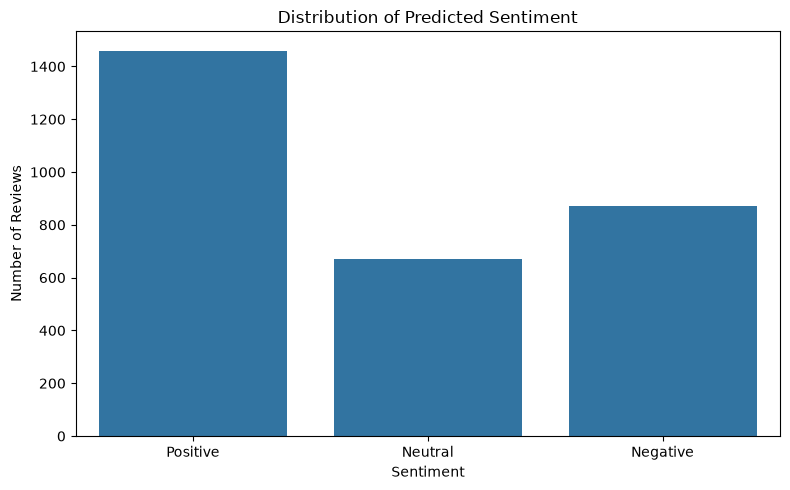

In [9]:

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Predicted_Sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Distribution of Predicted Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


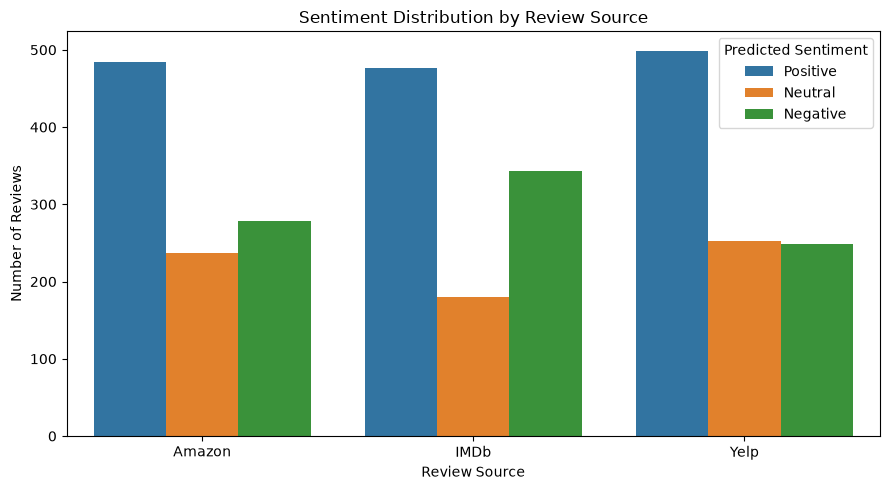

In [10]:

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Source",
    hue="Predicted_Sentiment",
    hue_order=["Positive", "Neutral", "Negative"]
)

plt.title("Sentiment Distribution by Review Source")
plt.xlabel("Review Source")
plt.ylabel("Number of Reviews")
plt.legend(title="Predicted Sentiment")
plt.tight_layout()
plt.show()


In [11]:


# Exclude neutral predictions for this binary comparison
comparison_df = df[
    df["Predicted_Sentiment"] != "Neutral"
].copy()

comparison_df["Original_Sentiment"] = (
    comparison_df["Original_Label"]
    .map({0: "Negative", 1: "Positive"})
)

comparison_table = pd.crosstab(
    comparison_df["Original_Sentiment"],
    comparison_df["Predicted_Sentiment"],
    rownames=["Original Label"],
    colnames=["VADER Prediction"]
)

display(comparison_table)



VADER Prediction,Negative,Positive
Original Label,,
Negative,803,261
Positive,67,1199


In [12]:

# calculating the accuracy on those non-neutral reviews:

correct = (
    comparison_df["Original_Sentiment"]
    == comparison_df["Predicted_Sentiment"]
).sum()

accuracy = correct / len(comparison_df) * 100

print(f"Non-neutral reviews evaluated: {len(comparison_df)}")
print(f"Accuracy on non-neutral reviews: {accuracy:.2f}%")


Non-neutral reviews evaluated: 2330
Accuracy on non-neutral reviews: 85.92%


In [13]:
# Create an output folder
os.makedirs("output", exist_ok=True)

# Save all reviews and their sentiment scores
df.to_csv("output/sentiment_analysis_results.csv", index=False)

# Save the sentiment counts
sentiment_summary = (
    df["Predicted_Sentiment"]
    .value_counts()
    .rename_axis("Sentiment")
    .reset_index(name="Number_of_Reviews")
)

sentiment_summary.to_csv(
    "output/sentiment_summary.csv",
    index=False
)

print("Files saved successfully!")
print("1. output/sentiment_analysis_results.csv")
print("2. output/sentiment_summary.csv")


Files saved successfully!
1. output/sentiment_analysis_results.csv
2. output/sentiment_summary.csv


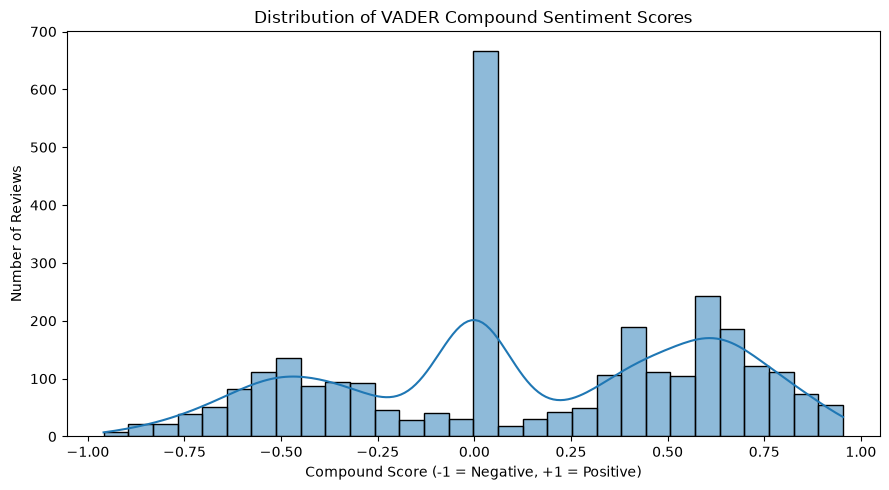

Final visualization saved!


In [14]:

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Compound_Score",
    bins=30,
    kde=True
)

plt.title("Distribution of VADER Compound Sentiment Scores")
plt.xlabel("Compound Score (-1 = Negative, +1 = Positive)")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig("output/compound_sentiment_distribution.png", dpi=300)
plt.show()

print("Final visualization saved!")
